# Notebook 04 - XGBoost

Scope: train and evaluate XGBoost only using the current preprocessing outputs from `run_pipeline(force_ingestion=False, use_database=False)`. The model consumes only `outputs["tree"]`. Validation is used for threshold sensitivity and threshold selection; test is evaluated once after the selected threshold is fixed.

## 1. Imports

In [16]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=UserWarning)

RANDOM_STATE = 42
DEFAULT_THRESHOLD = 0.50
TARGET_RECALL = 0.85
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)
TOP_N_FEATURES = 15

## 2. Path and Output Setup

In [17]:
def find_source_root(start_path: Path) -> Path:
    current = start_path.resolve()
    for candidate in [current, *current.parents]:
        if candidate.name == 'Source':
            return candidate
        nested = candidate / 'Source'
        if nested.exists() and nested.is_dir():
            return nested.resolve()
    raise FileNotFoundError('Could not locate Source from the current working directory.')


CURRENT_WORKING_DIRECTORY = Path.cwd().resolve()
SOURCE_ROOT = find_source_root(CURRENT_WORKING_DIRECTORY)
REPO_ROOT = SOURCE_ROOT.parent
TARGET_NOTEBOOK_PATH = SOURCE_ROOT / 'notebooks' / '04_xgboost_models_train.ipynb'

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from Source.src.path import (  # noqa: E402
    DATA_REPORTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    NOTEBOOKS_DIR,
    PROJECT_ROOT,
    REPORTS_DIR,
    TEST_DATA_FILE,
    TRAIN_DATA_FILE,
    VALIDATION_DATA_FILE,
)
from Source.src.utils.feature_display import build_feature_mapping_table  # noqa: E402

DATA_REPORTS_DIR = Path(DATA_REPORTS_DIR)
FIGURES_DIR = Path(FIGURES_DIR)
MODELS_DIR = Path(MODELS_DIR)

print(f'Current working directory: {CURRENT_WORKING_DIRECTORY}')
print(f'Source project root: {SOURCE_ROOT}')
print(f'Target notebook path: {TARGET_NOTEBOOK_PATH}')

path_checks = pd.DataFrame(
    [
        {'name': 'PROJECT_ROOT', 'path': Path(PROJECT_ROOT), 'exists': Path(PROJECT_ROOT).exists()},
        {'name': 'NOTEBOOKS_DIR', 'path': Path(NOTEBOOKS_DIR), 'exists': Path(NOTEBOOKS_DIR).exists()},
        {'name': 'REPORTS_DIR', 'path': Path(REPORTS_DIR), 'exists': Path(REPORTS_DIR).exists()},
        {'name': 'DATA_REPORTS_DIR', 'path': DATA_REPORTS_DIR, 'exists': DATA_REPORTS_DIR.exists()},
        {'name': 'FIGURES_DIR', 'path': FIGURES_DIR, 'exists': FIGURES_DIR.exists()},
        {'name': 'MODELS_DIR', 'path': MODELS_DIR, 'exists': MODELS_DIR.exists()},
        {'name': 'TRAIN_DATA_FILE', 'path': Path(TRAIN_DATA_FILE), 'exists': Path(TRAIN_DATA_FILE).exists()},
        {'name': 'VALIDATION_DATA_FILE', 'path': Path(VALIDATION_DATA_FILE), 'exists': Path(VALIDATION_DATA_FILE).exists()},
        {'name': 'TEST_DATA_FILE', 'path': Path(TEST_DATA_FILE), 'exists': Path(TEST_DATA_FILE).exists()},
    ]
)
display(path_checks)

missing_required_paths = path_checks.loc[~path_checks['exists'], 'name'].tolist()
if missing_required_paths:
    raise FileNotFoundError(f'Missing required paths before run_pipeline: {missing_required_paths}')

print('All required folders and checkpoint files exist. Safe to call run_pipeline without ingestion.')

Current working directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\notebooks
Refactor project root: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2
Target notebook path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\notebooks\04_xgboost_models_train.ipynb
Legacy root notebook path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\notebooks\04_xgboost_models_train.ipynb
Legacy root notebook exists: True


,name,path,exists
0,PROJECT_ROOT,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
1,NOTEBOOKS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
2,REPORTS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
3,DATA_REPORTS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
4,FIGURES_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
5,MODELS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
6,TRAIN_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
7,VALIDATION_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
8,TEST_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True


All required folders and checkpoint files exist. Safe to call run_pipeline without ingestion.


## 3. Notebook-Local Helpers

In [18]:
def display_and_save_table(df: pd.DataFrame, filename: str, description: str | None = None) -> Path:
    path = DATA_REPORTS_DIR / filename
    df.to_csv(path, index=False)
    if description:
        print(description)
    display(df)
    print(f'Table shape: {df.shape}')
    print(f'Saved table: {path}')
    return path


def save_current_figure(filename: str, dpi: int = 300) -> Path:
    path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=dpi, bbox_inches='tight')
    print(f'Saved figure: {path}')
    display(plt.gcf())
    plt.close()
    return path


def evaluate_binary_classifier(
    y_true: pd.Series,
    y_proba: np.ndarray,
    threshold: float,
    split_name: str,
    model_name: str = 'XGBoost',
) -> pd.DataFrame:
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    metrics = {
        'Model': model_name,
        'Split': split_name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1_Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, y_proba),
        'PR_AUC': average_precision_score(y_true, y_proba),
        'TP': int(tp),
        'FP': int(fp),
        'TN': int(tn),
        'FN': int(fn),
        'False_Positive_Rate': fp / (fp + tn) if (fp + tn) else 0.0,
        'False_Negative_Rate': fn / (fn + tp) if (fn + tp) else 0.0,
    }
    return pd.DataFrame([metrics])


def build_confusion_matrix_table(
    y_true: pd.Series,
    y_proba: np.ndarray,
    threshold: float,
    split_name: str,
) -> pd.DataFrame:
    y_pred = (y_proba >= threshold).astype(int)
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    rows = []
    for actual_index, actual_label in enumerate([0, 1]):
        for predicted_index, predicted_label in enumerate([0, 1]):
            rows.append(
                {
                    'Split': split_name,
                    'Threshold': threshold,
                    'Actual': actual_label,
                    'Predicted': predicted_label,
                    'Count': int(matrix[actual_index, predicted_index]),
                }
            )
    return pd.DataFrame(rows)


def build_classification_report_table(
    y_true: pd.Series,
    y_proba: np.ndarray,
    threshold: float,
    split_name: str,
) -> pd.DataFrame:
    y_pred = (y_proba >= threshold).astype(int)
    report = classification_report(y_true, y_pred, labels=[0, 1], output_dict=True, zero_division=0)
    rows = []
    for label, values in report.items():
        if isinstance(values, dict):
            row = {'Split': split_name, 'Threshold': threshold, 'Class': label}
            row.update(values)
            rows.append(row)
        else:
            rows.append(
                {
                    'Split': split_name,
                    'Threshold': threshold,
                    'Class': label,
                    'precision': values,
                    'recall': values,
                    'f1-score': values,
                    'support': values,
                }
            )
    return pd.DataFrame(rows)


def scan_thresholds(y_true: pd.Series, y_proba: np.ndarray, thresholds: np.ndarray) -> pd.DataFrame:
    rows = []
    for threshold in thresholds:
        metrics = evaluate_binary_classifier(y_true, y_proba, float(threshold), split_name='validation')
        rows.append(metrics.iloc[0].to_dict())
    result = pd.DataFrame(rows)
    result['Meets_Recall_Target'] = result['Recall'] >= TARGET_RECALL
    return result


def select_threshold(threshold_table: pd.DataFrame) -> tuple[float, pd.Series, str]:
    eligible = threshold_table[threshold_table['Recall'] >= TARGET_RECALL].copy()
    if not eligible.empty:
        max_f1 = eligible['F1_Score'].max()
        near_best = eligible[eligible['F1_Score'] >= max_f1 - 1e-6]
        selected = near_best.sort_values(['Precision', 'Threshold'], ascending=[False, False]).iloc[0]
        rule = 'Recall target met; selected highest F1-score, with near ties resolved by higher precision.'
    else:
        selected = threshold_table.sort_values(['Recall', 'F1_Score', 'Precision'], ascending=[False, False, False]).iloc[0]
        rule = 'Recall target not met; selected highest recall, with ties resolved by F1-score and precision.'
    return float(selected['Threshold']), selected, rule


def plot_confusion_matrix_from_values(
    y_true: pd.Series,
    y_proba: np.ndarray,
    threshold: float,
    title: str,
) -> None:
    y_pred = (y_proba >= threshold).astype(int)
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(matrix, cmap='Blues')
    ax.set_title(title)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['No Churn', 'Churn'])
    ax.set_yticklabels(['No Churn', 'Churn'])
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            value = matrix[row, col]
            text_color = 'white' if value > matrix.max() / 2 else 'black'
            ax.text(col, row, f'{value:,}', ha='center', va='center', color=text_color, fontsize=12)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)


def plot_threshold_sensitivity(threshold_table: pd.DataFrame, selected_threshold: float) -> None:
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(threshold_table['Threshold'], threshold_table['Precision'], label='Precision', linewidth=2)
    ax.plot(threshold_table['Threshold'], threshold_table['Recall'], label='Recall', linewidth=2)
    ax.plot(threshold_table['Threshold'], threshold_table['F1_Score'], label='F1-score', linewidth=2)
    ax.axhline(TARGET_RECALL, color='gray', linestyle='--', linewidth=1.5, label=f'Target recall {TARGET_RECALL:.2f}')
    ax.axvline(selected_threshold, color='black', linestyle=':', linewidth=2, label=f'Selected threshold {selected_threshold:.2f}')
    ax.set_title('XGBoost Validation Threshold Sensitivity')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Metric value')
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(loc='best')


def plot_roc_curve(y_true: pd.Series, y_proba: np.ndarray) -> None:
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auc_value = roc_auc_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(fpr, tpr, linewidth=2, label=f'ROC-AUC = {auc_value:.3f}')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
    ax.set_title('XGBoost Validation ROC Curve')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.grid(alpha=0.25)
    ax.legend(loc='lower right')


def plot_precision_recall_curve(y_true: pd.Series, y_proba: np.ndarray) -> None:
    precision, recall, _ = precision_recall_curve(y_true, y_proba)
    pr_auc = average_precision_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(recall, precision, linewidth=2, label=f'PR-AUC = {pr_auc:.3f}')
    ax.set_title('XGBoost Validation Precision-Recall Curve')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.grid(alpha=0.25)
    ax.legend(loc='best')


def build_gain_importance_table(model: XGBClassifier, feature_columns: pd.Index) -> tuple[pd.DataFrame, str]:
    booster = model.get_booster()
    raw_scores = booster.get_score(importance_type='gain')
    feature_columns = pd.Index(feature_columns)
    booster_feature_names = booster.feature_names
    if booster_feature_names is not None:
        if len(booster_feature_names) != len(feature_columns):
            raise ValueError('XGBoost booster feature count differs from X_train.columns.')
        if list(booster_feature_names) != list(feature_columns):
            raise ValueError('XGBoost booster feature order differs from X_train.columns.')
        xgboost_feature_keys = list(booster_feature_names)
    else:
        xgboost_feature_keys = [f'f{index}' for index in range(len(feature_columns))]

    importance_values = [float(raw_scores.get(key, 0.0)) for key in xgboost_feature_keys]
    mapping = build_feature_mapping_table(feature_columns)
    importance_table = mapping.copy()
    importance_table.insert(0, 'XGBoost_Feature_Key', xgboost_feature_keys)
    importance_table.insert(1, 'Feature_Position', np.arange(len(feature_columns)))
    importance_table.insert(2, 'X_train_Column', feature_columns)
    importance_table.insert(3, 'Raw_Feature_Name', feature_columns)
    importance_table['Importance'] = importance_values
    importance_table = importance_table.sort_values('Importance', ascending=False).reset_index(drop=True)
    importance_table['Rank'] = np.arange(1, len(importance_table) + 1)
    ordered_columns = [
        'XGBoost_Feature_Key',
        'Feature_Position',
        'X_train_Column',
        'Raw_Feature_Name',
        'Feature_Code',
        'Feature_Display_Name',
        'Base_Feature',
        'Base_Feature_Display_Name',
        'Encoded_Category',
        'Encoded_Category_Display_Name',
        'Feature_Group',
        'Feature_Type',
        'Importance',
        'Rank',
    ]
    return importance_table[ordered_columns], 'gain'


def plot_feature_importance_barh(feature_importance_table: pd.DataFrame, top_n: int = TOP_N_FEATURES) -> None:
    plot_df = feature_importance_table.head(top_n).iloc[::-1]
    fig_height = max(6, top_n * 0.42)
    fig, ax = plt.subplots(figsize=(9, fig_height))
    ax.barh(plot_df['Feature_Display_Name'], plot_df['Importance'], color='#3563a8')
    ax.set_title(f'XGBoost Top {top_n} Gain-Based Feature Importance')
    ax.set_xlabel('Mean gain importance')
    ax.set_ylabel('')
    ax.grid(axis='x', alpha=0.25)


def plot_cumulative_feature_importance(feature_importance_table: pd.DataFrame) -> None:
    plot_df = feature_importance_table.copy()
    total_importance = plot_df['Importance'].sum()
    if total_importance > 0:
        plot_df['Cumulative_Importance'] = plot_df['Importance'].cumsum() / total_importance
    else:
        plot_df['Cumulative_Importance'] = 0.0
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(plot_df['Rank'], plot_df['Cumulative_Importance'], marker='o', linewidth=2)
    ax.axhline(0.80, color='gray', linestyle='--', linewidth=1.5, label='80% cumulative importance')
    ax.set_title('XGBoost Cumulative Feature Importance')
    ax.set_xlabel('Feature rank')
    ax.set_ylabel('Cumulative share of gain importance')
    ax.set_ylim(0, 1.05)
    ax.set_xticks(plot_df['Rank'])
    ax.grid(alpha=0.25)
    ax.legend(loc='lower right')

## 4. Load Pipeline Outputs

In [19]:
from Source.src.main import run_pipeline

result = run_pipeline(force_ingestion=False, use_database=False)
builder = result['builder']
outputs = result['outputs']

tree_train = outputs['tree']['train']
tree_val = outputs['tree']['validation']
tree_test = outputs['tree']['test']

print('Tree branch shapes:')
print(f'train: {tree_train.shape}')
print(f'validation: {tree_val.shape}')
print(f'test: {tree_test.shape}')
print("Pipeline output branch used for modeling: outputs['tree']")

2026-07-13 16:54:55,194 - main - [INFO] - Refactored churn pipeline orchestration started.
2026-07-13 16:54:55,195 - main - [INFO] - Run options: force_ingestion=False, use_database=False, view_name=None
2026-07-13 16:54:55,196 - main - [INFO] - Train checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\train_df.csv
2026-07-13 16:54:55,197 - main - [INFO] - Validation checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\validation_df.csv
2026-07-13 16:54:55,199 - main - [INFO] - Test checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\test_df.csv
2026-07-13 16:54:55,200 - main - [INFO] - All checkpoint files exist; ingestion skipped.
2026-07-13 16:54:55,229 - main - [INFO] - Loaded train checkpoint shape: (4930, 16)
2026-07-13 16:54:55,230 - main - [INFO] - Loaded validation checkpoint shape: (1056,

All required project directories are available.


2026-07-13 16:54:55,454 - main - [INFO] - Logistic train output shape: (4930, 28)
2026-07-13 16:54:55,454 - main - [INFO] - Logistic validation output shape: (1056, 28)
2026-07-13 16:54:55,454 - main - [INFO] - Logistic test output shape: (1057, 28)
2026-07-13 16:54:55,454 - main - [INFO] - Tree train output shape: (4930, 20)
2026-07-13 16:54:55,454 - main - [INFO] - Tree validation output shape: (1056, 20)
2026-07-13 16:54:55,454 - main - [INFO] - Tree test output shape: (1057, 20)
2026-07-13 16:54:55,454 - main - [INFO] - Preprocessing branch orchestration completed.
2026-07-13 16:54:55,454 - main - [INFO] - Refactored churn pipeline orchestration finished.


Tree branch shapes:
train: (4930, 20)
validation: (1056, 20)
test: (1057, 20)
Pipeline output branch used for modeling: outputs['tree']


## 5. Tree Branch Data Validation

In [20]:
EXPECTED_TREE_DIMS = {
    'train': (4930, 20),
    'validation': (1056, 20),
    'test': (1057, 20),
}


def display_tree_branch_checks(name: str, df: pd.DataFrame) -> None:
    print(f'{name} shape: {df.shape}')
    print(f'{name} row count: {df.shape[0]}')
    print(f'{name} column count: {df.shape[1]}')
    print(f'{name} column names:')
    print(df.columns.tolist())
    print(f'{name} head:')
    display(df.head())

    dtype_summary = df.dtypes.astype(str).value_counts().rename_axis('dtype').reset_index(name='column_count')
    print(f'{name} dtypes summary:')
    display(dtype_summary)
    display(pd.DataFrame({'column': df.columns, 'dtype': df.dtypes.astype(str).values}))

    print(f"{name} ID exists: {'ID' in df.columns}")
    print(f"{name} Churn exists: {'Churn' in df.columns}")
    object_columns = df.select_dtypes(include='object').columns.tolist()
    print(f'{name} object columns: {object_columns}')

    missing_summary = (
        df.isna()
        .sum()
        .rename('missing_count')
        .reset_index()
        .rename(columns={'index': 'column'})
    )
    missing_summary['missing_rate'] = missing_summary['missing_count'] / len(df)
    print(f'{name} missing values summary:')
    display(missing_summary)
    print(f"{name} total missing values: {int(missing_summary['missing_count'].sum())}")

    churn_distribution = df['Churn'].value_counts().sort_index().rename_axis('Churn').reset_index(name='count')
    churn_distribution['rate'] = churn_distribution['count'] / churn_distribution['count'].sum()
    print(f'{name} Churn distribution:')
    display(churn_distribution)


for split_name, frame in [('train', tree_train), ('validation', tree_val), ('test', tree_test)]:
    expected_shape = EXPECTED_TREE_DIMS[split_name]
    if frame.shape != expected_shape:
        raise ValueError(f'{split_name} tree shape mismatch: expected {expected_shape}, got {frame.shape}')
    if 'ID' not in frame.columns or 'Churn' not in frame.columns:
        raise ValueError(f'{split_name} tree output must include ID and Churn columns.')
    display_tree_branch_checks(f'tree_{split_name}', frame)

tree_train shape: (4930, 20)
tree_train row count: 4930
tree_train column count: 20
tree_train column names:
['ID', 'Churn', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'tenure_group', 'service_diversity', 'monthly_charges_ratio', 'is_paperless_electronic']
tree_train head:


,ID,Churn,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaymentMethod,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,tenure_group,service_diversity,monthly_charges_ratio,is_paperless_electronic
0,7883-ROJOC,0,0,1.0,0.0,19,0.0,3.0,0.0,44.9,839.65,0.0,0.0,0.0,0.0,0.0,1.0,0,0.693781,0
1,3164-AALRN,1,0,0.0,0.0,5,1.0,3.0,1.0,70.0,347.40,0.0,0.0,0.0,1.0,0.0,0.0,1,1.081619,0
2,9821-POOTN,1,0,1.0,0.0,35,0.0,2.0,1.0,75.2,2576.20,1.0,0.0,0.0,0.0,0.0,2.0,0,1.161968,0
3,3259-QMXUN,0,0,1.0,0.0,58,2.0,2.0,1.0,86.1,4890.50,0.0,1.0,1.0,1.0,0.0,4.0,3,1.330392,0
4,1226-UDFZR,1,0,0.0,0.0,2,0.0,3.0,1.0,49.6,114.70,0.0,0.0,1.0,0.0,0.0,0.0,1,0.766404,0


tree_train dtypes summary:


,dtype,column_count
0,float64,14
1,int64,5
2,object,1


,column,dtype
0,ID,object
1,Churn,int64
2,SeniorCitizen,int64
3,Partner,float64
4,Dependents,float64
5,Tenure,int64
6,Contract,float64
7,PaymentMethod,float64
8,PaperlessBilling,float64
9,MonthlyCharges,float64


tree_train ID exists: True
tree_train Churn exists: True
tree_train object columns: ['ID']
tree_train missing values summary:


... (17 outputs left out)

tree_test ID exists: True
tree_test Churn exists: True
tree_test object columns: ['ID']
tree_test missing values summary:


,column,missing_count,missing_rate
0,ID,0,0.0
1,Churn,0,0.0
2,SeniorCitizen,0,0.0
3,Partner,0,0.0
4,Dependents,0,0.0
5,Tenure,0,0.0
6,Contract,0,0.0
7,PaymentMethod,0,0.0
8,PaperlessBilling,0,0.0
9,MonthlyCharges,0,0.0


tree_test total missing values: 0
tree_test Churn distribution:


,Churn,count,rate
0,0,776,0.734153
1,1,281,0.265847


## 6. X/y Split

In [21]:
X_train = tree_train.drop(columns=['ID', 'Churn'])
y_train = tree_train['Churn'].astype(int)

X_val = tree_val.drop(columns=['ID', 'Churn'])
y_val = tree_val['Churn'].astype(int)

X_test = tree_test.drop(columns=['ID', 'Churn'])
y_test = tree_test['Churn'].astype(int)

EXPECTED_X_DIMS = {
    'train': (4930, 18),
    'validation': (1056, 18),
    'test': (1057, 18),
}

print(f'X_train.shape: {X_train.shape}')
print(f'X_val.shape: {X_val.shape}')
print(f'X_test.shape: {X_test.shape}')
print(f'y_train.shape: {y_train.shape}')
print(f'y_val.shape: {y_val.shape}')
print(f'y_test.shape: {y_test.shape}')

for label, frame in [('train', X_train), ('validation', X_val), ('test', X_test)]:
    expected_shape = EXPECTED_X_DIMS[label]
    if frame.shape != expected_shape:
        raise ValueError(f'X_{label} shape mismatch: expected {expected_shape}, got {frame.shape}')
    print(f"ID not in X_{label}.columns: {'ID' not in frame.columns}")
    print(f"Churn not in X_{label}.columns: {'Churn' not in frame.columns}")
    if 'ID' in frame.columns or 'Churn' in frame.columns:
        raise ValueError(f'X_{label} still contains ID or Churn.')

object_columns_in_x = X_train.select_dtypes(include='object').columns.tolist()
print(f'Object columns in X_train: {object_columns_in_x}')
if object_columns_in_x:
    raise TypeError(f'X_train contains object columns that XGBoost should not receive: {object_columns_in_x}')

print('Model input feature columns remain unchanged before fitting:')
print(X_train.columns.tolist())
print('X_train head:')
display(X_train.head())
print('y_train value counts:')
display(y_train.value_counts().sort_index().rename_axis('Churn').reset_index(name='count'))

X_train.shape: (4930, 18)
X_val.shape: (1056, 18)
X_test.shape: (1057, 18)
y_train.shape: (4930,)
y_val.shape: (1056,)
y_test.shape: (1057,)
ID not in X_train.columns: True
Churn not in X_train.columns: True
ID not in X_validation.columns: True
Churn not in X_validation.columns: True
ID not in X_test.columns: True
Churn not in X_test.columns: True
Object columns in X_train: []
Model input feature columns remain unchanged before fitting:
['SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'tenure_group', 'service_diversity', 'monthly_charges_ratio', 'is_paperless_electronic']
X_train head:


,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaymentMethod,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,tenure_group,service_diversity,monthly_charges_ratio,is_paperless_electronic
0,0,1.0,0.0,19,0.0,3.0,0.0,44.9,839.65,0.0,0.0,0.0,0.0,0.0,1.0,0,0.693781,0
1,0,0.0,0.0,5,1.0,3.0,1.0,70.0,347.40,0.0,0.0,0.0,1.0,0.0,0.0,1,1.081619,0
2,0,1.0,0.0,35,0.0,2.0,1.0,75.2,2576.20,1.0,0.0,0.0,0.0,0.0,2.0,0,1.161968,0
3,0,1.0,0.0,58,2.0,2.0,1.0,86.1,4890.50,0.0,1.0,1.0,1.0,0.0,4.0,3,1.330392,0
4,0,0.0,0.0,2,0.0,3.0,1.0,49.6,114.70,0.0,0.0,1.0,0.0,0.0,0.0,1,0.766404,0


y_train value counts:


,Churn,count
0,0,3622
1,1,1308


## 7. Train XGBoost

In [22]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count
print(f'Training class counts: negative={negative_count}, positive={positive_count}')
print(f'scale_pos_weight from training only: {scale_pos_weight:.6f}')

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)
validation_proba = xgb_model.predict_proba(X_val)[:, 1]
default_validation_predictions = (validation_proba >= DEFAULT_THRESHOLD).astype(int)

print('XGBoost trained.')
print(f'Model parameters: {xgb_model.get_params()}')
print(f'Validation probability array shape: {validation_proba.shape}')
print(f'Validation default prediction threshold: {DEFAULT_THRESHOLD}')

Training class counts: negative=3622, positive=1308
scale_pos_weight from training only: 2.769113
XGBoost trained.
Model parameters: {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.9, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 4, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 300, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': 2.7691131498470947, 'subsample': 0.9, 't

## 8. Validation Evaluation at Default Threshold 0.50

Validation metrics at default threshold 0.50


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate
0,XGBoost,validation,0.5,0.761364,0.533493,0.796429,0.638968,0.854375,0.665582,223,195,581,57,0.251289,0.203571


Table shape: (1, 15)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_default_threshold_validation_metrics.csv
Validation confusion matrix table at default threshold 0.50


,Split,Threshold,Actual,Predicted,Count
0,validation,0.5,0,0,581
1,validation,0.5,0,1,195
2,validation,0.5,1,0,57
3,validation,0.5,1,1,223


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_validation_confusion_matrix_default_threshold.csv
Validation classification report at default threshold 0.50


,Split,Threshold,Class,precision,recall,f1-score,support
0,validation,0.5,0,0.910658,0.748711,0.821782,776.000000
1,validation,0.5,1,0.533493,0.796429,0.638968,280.000000
2,validation,0.5,accuracy,0.761364,0.761364,0.761364,0.761364
3,validation,0.5,macro avg,0.722076,0.772570,0.730375,1056.000000
4,validation,0.5,weighted avg,0.810652,0.761364,0.773309,1056.000000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_validation_classification_report_default_threshold.csv
Classification report at validation threshold 0.50:
              precision    recall  f1-score   support

           0       0.91      0.75      0.82       776
           1       0.53      0.80      0.64       280

    accuracy                           0.76      1056
   macro avg       0.72      0.77      0.73      1056
weighted avg       0.81      0.76      0.77      1056

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\xgboost_01_validation_confusion_matrix_default_threshold.png


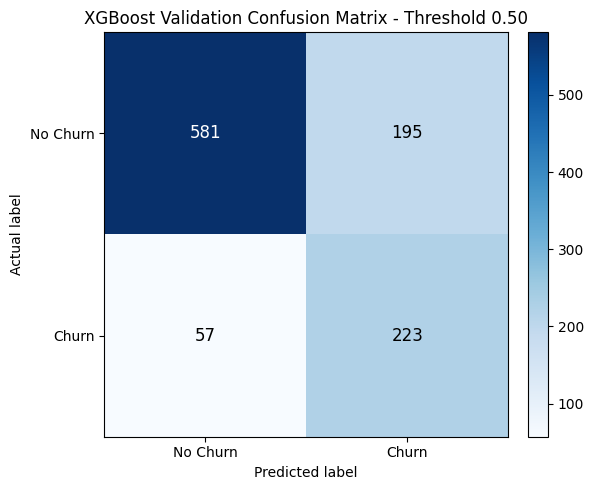

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/xgboost_01_validation_confusion_matrix_default_threshold.png')

In [23]:
default_validation_metrics = evaluate_binary_classifier(
    y_val,
    validation_proba,
    threshold=DEFAULT_THRESHOLD,
    split_name='validation',
)
display_and_save_table(
    default_validation_metrics,
    'xgboost_default_threshold_validation_metrics.csv',
    'Validation metrics at default threshold 0.50',
)

validation_confusion_default = build_confusion_matrix_table(
    y_val,
    validation_proba,
    threshold=DEFAULT_THRESHOLD,
    split_name='validation',
)
display_and_save_table(
    validation_confusion_default,
    'xgboost_validation_confusion_matrix_default_threshold.csv',
    'Validation confusion matrix table at default threshold 0.50',
)

validation_report_default = build_classification_report_table(
    y_val,
    validation_proba,
    threshold=DEFAULT_THRESHOLD,
    split_name='validation',
)
display_and_save_table(
    validation_report_default,
    'xgboost_validation_classification_report_default_threshold.csv',
    'Validation classification report at default threshold 0.50',
)

print('Classification report at validation threshold 0.50:')
print(classification_report(y_val, default_validation_predictions, zero_division=0))

plot_confusion_matrix_from_values(
    y_val,
    validation_proba,
    DEFAULT_THRESHOLD,
    'XGBoost Validation Confusion Matrix - Threshold 0.50',
)
save_current_figure('xgboost_01_validation_confusion_matrix_default_threshold.png')

## 9. Validation-Only Threshold Sensitivity Analysis

Threshold Sensitivity Analysis on validation data


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Meets_Recall_Target
0,XGBoost,validation,0.05,0.514205,0.351970,0.989286,0.519213,0.854375,0.665582,277,510,266,3,0.657216,0.010714,True
1,XGBoost,validation,0.06,0.531250,0.360208,0.989286,0.528122,0.854375,0.665582,277,492,284,3,0.634021,0.010714,True
2,XGBoost,validation,0.07,0.538826,0.363636,0.985714,0.531280,0.854375,0.665582,276,483,293,4,0.622423,0.014286,True
3,XGBoost,validation,0.08,0.556818,0.372629,0.982143,0.540275,0.854375,0.665582,275,463,313,5,0.596649,0.017857,True
4,XGBoost,validation,0.09,0.567235,0.377931,0.978571,0.545274,0.854375,0.665582,274,451,325,6,0.581186,0.021429,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86,XGBoost,validation,0.91,0.763258,0.857143,0.128571,0.223602,0.854375,0.665582,36,6,770,244,0.007732,0.871429,False
87,XGBoost,validation,0.92,0.755682,0.843750,0.096429,0.173077,0.854375,0.665582,27,5,771,253,0.006443,0.903571,False
88,XGBoost,validation,0.93,0.753788,0.884615,0.082143,0.150327,0.854375,0.665582,23,3,773,257,0.003866,0.917857,False
89,XGBoost,validation,0.94,0.748106,0.888889,0.057143,0.107383,0.854375,0.665582,16,2,774,264,0.002577,0.942857,False


Table shape: (91, 16)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_threshold_sensitivity_validation.csv
Selected threshold validation metrics


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Meets_Recall_Target,Target_Recall,Recall_Target_Met,Selection_Rule
0,XGBoost,validation,0.38,0.731061,0.495833,0.85,0.626316,0.854375,0.665582,238,242,534,42,0.311856,0.15,True,0.85,True,"Recall target met; selected highest F1-score, ..."


Table shape: (1, 19)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_selected_threshold_validation_metrics.csv
Validation confusion matrix table at selected threshold


,Split,Threshold,Actual,Predicted,Count
0,validation,0.38,0,0,534
1,validation,0.38,0,1,242
2,validation,0.38,1,0,42
3,validation,0.38,1,1,238


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_validation_confusion_matrix_selected_threshold.csv
Validation classification report at selected threshold


,Split,Threshold,Class,precision,recall,f1-score,support
0,validation,0.38,0,0.927083,0.688144,0.789941,776.000000
1,validation,0.38,1,0.495833,0.850000,0.626316,280.000000
2,validation,0.38,accuracy,0.731061,0.731061,0.731061,0.731061
3,validation,0.38,macro avg,0.711458,0.769072,0.708128,1056.000000
4,validation,0.38,weighted avg,0.812737,0.731061,0.746555,1056.000000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_validation_classification_report_selected_threshold.csv
Selected validation threshold: 0.38
Threshold selection rule: Recall target met; selected highest F1-score, with near ties resolved by higher precision.
Recall target met: True
Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\xgboost_02_threshold_sensitivity_validation.png


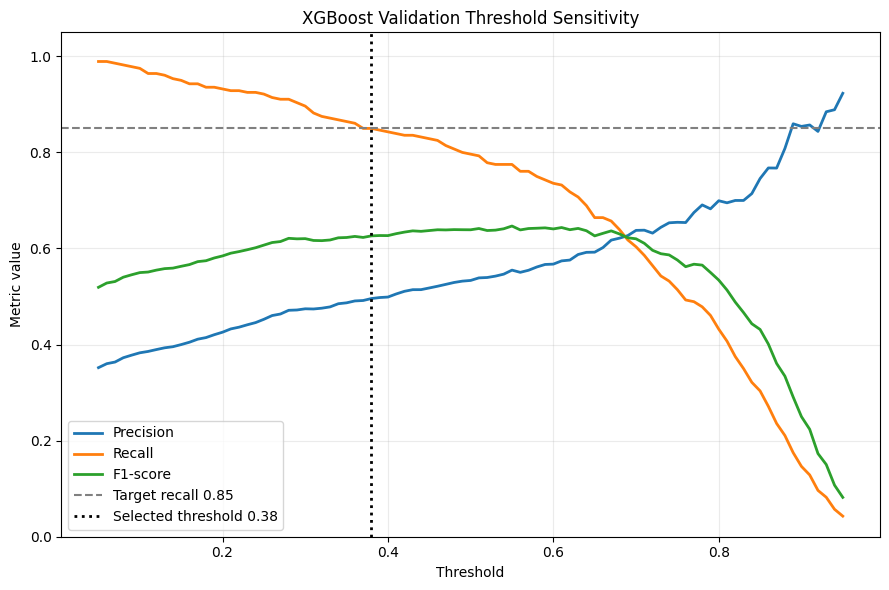

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/xgboost_02_threshold_sensitivity_validation.png')

In [24]:
threshold_sensitivity_validation = scan_thresholds(
    y_val,
    validation_proba,
    THRESHOLDS,
)
display_and_save_table(
    threshold_sensitivity_validation,
    'xgboost_threshold_sensitivity_validation.csv',
    'Threshold Sensitivity Analysis on validation data',
)

selected_threshold, selected_threshold_row, threshold_selection_rule = select_threshold(threshold_sensitivity_validation)
selected_validation_metrics = evaluate_binary_classifier(
    y_val,
    validation_proba,
    threshold=selected_threshold,
    split_name='validation',
)
selected_validation_metrics['Meets_Recall_Target'] = selected_validation_metrics['Recall'] >= TARGET_RECALL
selected_validation_metrics['Target_Recall'] = TARGET_RECALL
selected_validation_metrics['Recall_Target_Met'] = bool(selected_validation_metrics.loc[0, 'Meets_Recall_Target'])
selected_validation_metrics['Selection_Rule'] = threshold_selection_rule
display_and_save_table(
    selected_validation_metrics,
    'xgboost_selected_threshold_validation_metrics.csv',
    'Selected threshold validation metrics',
)

validation_confusion_selected = build_confusion_matrix_table(
    y_val,
    validation_proba,
    threshold=selected_threshold,
    split_name='validation',
)
display_and_save_table(
    validation_confusion_selected,
    'xgboost_validation_confusion_matrix_selected_threshold.csv',
    'Validation confusion matrix table at selected threshold',
)

validation_report_selected = build_classification_report_table(
    y_val,
    validation_proba,
    threshold=selected_threshold,
    split_name='validation',
)
display_and_save_table(
    validation_report_selected,
    'xgboost_validation_classification_report_selected_threshold.csv',
    'Validation classification report at selected threshold',
)

print(f'Selected validation threshold: {selected_threshold:.2f}')
print(f'Threshold selection rule: {threshold_selection_rule}')
print(f"Recall target met: {bool(selected_validation_metrics.loc[0, 'Recall_Target_Met'])}")

plot_threshold_sensitivity(threshold_sensitivity_validation, selected_threshold)
save_current_figure('xgboost_02_threshold_sensitivity_validation.png')

## 10. Validation ROC and Precision-Recall Curves

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\xgboost_03_roc_curve_validation.png


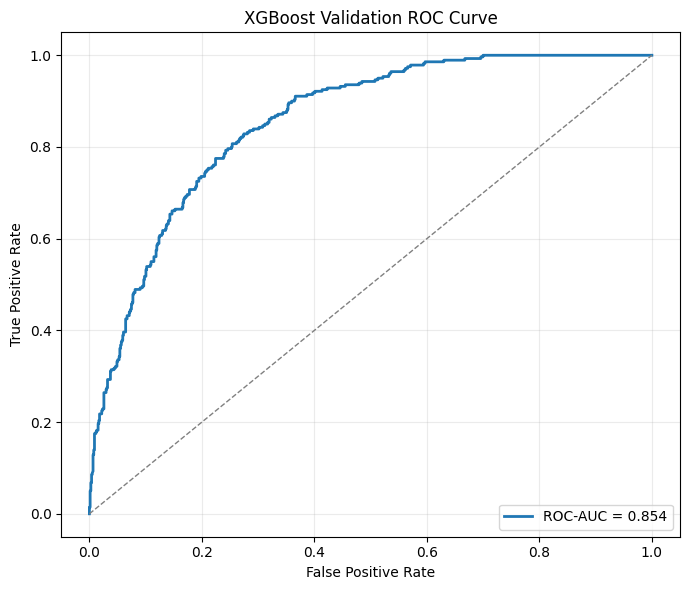

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\xgboost_04_precision_recall_curve_validation.png


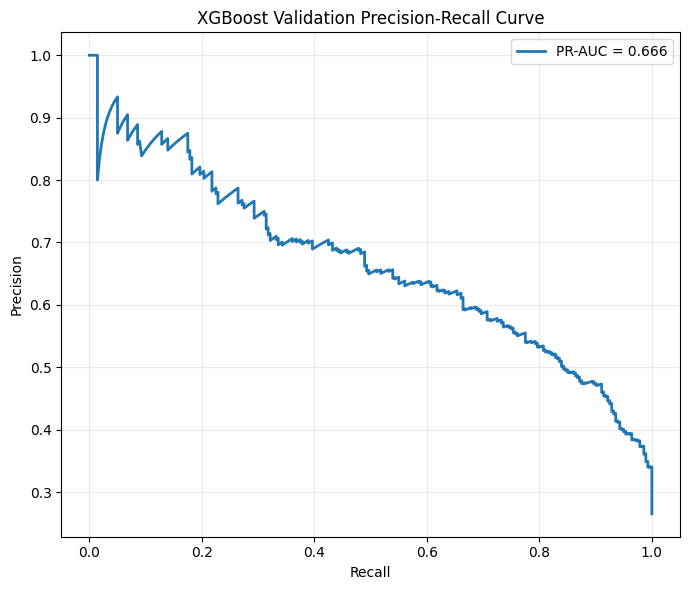

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/xgboost_04_precision_recall_curve_validation.png')

In [25]:
plot_roc_curve(y_val, validation_proba)
save_current_figure('xgboost_03_roc_curve_validation.png')

plot_precision_recall_curve(y_val, validation_proba)
save_current_figure('xgboost_04_precision_recall_curve_validation.png')

## 11. Final Test Evaluation Using Selected Threshold Only

Final test metrics using validation-selected threshold


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Threshold_Source
0,XGBoost,test,0.38,0.721854,0.486974,0.864769,0.623077,0.84116,0.65384,243,256,520,38,0.329897,0.135231,validation


Table shape: (1, 16)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_selected_threshold_test_metrics.csv
Final test confusion matrix table using validation-selected threshold


,Split,Threshold,Actual,Predicted,Count
0,test,0.38,0,0,520
1,test,0.38,0,1,256
2,test,0.38,1,0,38
3,test,0.38,1,1,243


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_test_confusion_matrix_selected_threshold.csv
Final test classification report using validation-selected threshold


,Split,Threshold,Class,precision,recall,f1-score,support
0,test,0.38,0,0.931900,0.670103,0.779610,776.000000
1,test,0.38,1,0.486974,0.864769,0.623077,281.000000
2,test,0.38,accuracy,0.721854,0.721854,0.721854,0.721854
3,test,0.38,macro avg,0.709437,0.767436,0.701344,1057.000000
4,test,0.38,weighted avg,0.813618,0.721854,0.737996,1057.000000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\xgboost_test_classification_report_selected_threshold.csv
Final test classification report using validation-selected threshold:
              precision    recall  f1-score   support

           0       0.93      0.67      0.78       776
           1       0.49      0.86      0.62       281

    accuracy                           0.72      1057
   macro avg       0.71      0.77      0.70      1057
weighted avg       0.81      0.72      0.74      1057

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\xgboost_05_test_confusion_matrix_selected_threshold.png


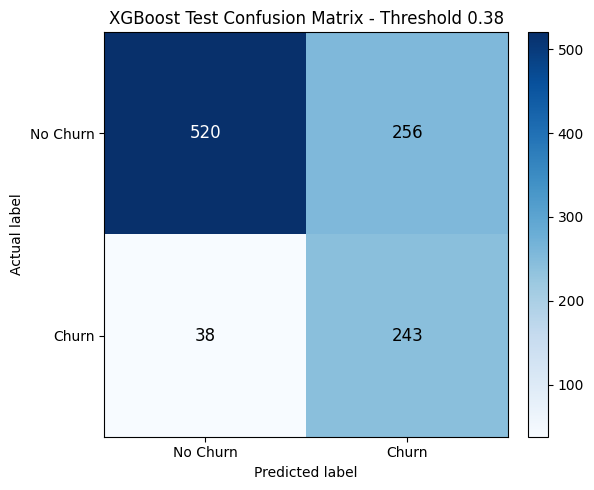

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/xgboost_05_test_confusion_matrix_selected_threshold.png')

In [26]:
test_proba = xgb_model.predict_proba(X_test)[:, 1]
final_test_metrics = evaluate_binary_classifier(
    y_test,
    test_proba,
    threshold=selected_threshold,
    split_name='test',
)
final_test_metrics['Threshold_Source'] = 'validation'
display_and_save_table(
    final_test_metrics,
    'xgboost_selected_threshold_test_metrics.csv',
    'Final test metrics using validation-selected threshold',
)

test_confusion_selected = build_confusion_matrix_table(
    y_test,
    test_proba,
    threshold=selected_threshold,
    split_name='test',
)
display_and_save_table(
    test_confusion_selected,
    'xgboost_test_confusion_matrix_selected_threshold.csv',
    'Final test confusion matrix table using validation-selected threshold',
)

test_report_selected = build_classification_report_table(
    y_test,
    test_proba,
    threshold=selected_threshold,
    split_name='test',
)
display_and_save_table(
    test_report_selected,
    'xgboost_test_classification_report_selected_threshold.csv',
    'Final test classification report using validation-selected threshold',
)

print('Final test classification report using validation-selected threshold:')
print(classification_report(y_test, (test_proba >= selected_threshold).astype(int), zero_division=0))

plot_confusion_matrix_from_values(
    y_test,
    test_proba,
    selected_threshold,
    f'XGBoost Test Confusion Matrix - Threshold {selected_threshold:.2f}',
)
save_current_figure('xgboost_05_test_confusion_matrix_selected_threshold.png')

## 12. Feature Importance

In [27]:
feature_name_mapping_xgboost = build_feature_mapping_table(X_train.columns)
required_tenure_mapping = {'Tenure': 'Tenure (Months)', 'tenure_group': 'Tenure Group'}
actual_tenure_mapping = feature_name_mapping_xgboost.set_index('Feature_Code')['Feature_Display_Name'].to_dict()
for feature_code, expected_label in required_tenure_mapping.items():
    if actual_tenure_mapping.get(feature_code) != expected_label:
        raise ValueError(f'Invalid tenure display mapping for {feature_code}: {actual_tenure_mapping.get(feature_code)}')
if feature_name_mapping_xgboost['Feature_Display_Name'].duplicated().any():
    raise ValueError('Duplicate XGBoost display labels detected.')
display_and_save_table(
    feature_name_mapping_xgboost,
    'feature_name_mapping_xgboost.csv',
    'Tree branch feature name mapping for XGBoost',
)

feature_importance_xgboost, importance_type_used = build_gain_importance_table(xgb_model, X_train.columns)
print(f'Feature importance type used: {importance_type_used}')
xgboost_feature_mapping_audit = feature_importance_xgboost[[
    'XGBoost_Feature_Key', 'Feature_Position', 'X_train_Column', 'Raw_Feature_Name',
    'Feature_Display_Name', 'Importance',
]].sort_values('Feature_Position').reset_index(drop=True)
display_and_save_table(
    xgboost_feature_mapping_audit,
    'xgboost_feature_mapping_audit.csv',
    'XGBoost raw-key to X_train feature mapping audit',
)
display_and_save_table(
    feature_importance_xgboost,
    'xgboost_feature_importance.csv',
    'XGBoost feature importance table',
)

top_feature_importance_xgboost = feature_importance_xgboost.head(TOP_N_FEATURES).copy()
display_and_save_table(
    top_feature_importance_xgboost,
    'xgboost_top_feature_importance.csv',
    f'Top {TOP_N_FEATURES} XGBoost feature importance table',
)

plot_feature_importance_barh(feature_importance_xgboost, top_n=TOP_N_FEATURES)
save_current_figure('xgboost_06_top_feature_importance.png')

plot_cumulative_feature_importance(feature_importance_xgboost)
save_current_figure('xgboost_07_cumulative_feature_importance.png')

ValueError: Invalid tenure display mapping for Tenure: Tenure

## 13. Save CSV Outputs

In [ ]:
expected_csv_outputs = [
    'xgboost_default_threshold_validation_metrics.csv',
    'xgboost_threshold_sensitivity_validation.csv',
    'xgboost_selected_threshold_validation_metrics.csv',
    'xgboost_selected_threshold_test_metrics.csv',
    'xgboost_feature_importance.csv',
    'xgboost_top_feature_importance.csv',
    'feature_name_mapping_xgboost.csv',
    'xgboost_feature_mapping_audit.csv',
    'xgboost_validation_confusion_matrix_default_threshold.csv',
    'xgboost_validation_confusion_matrix_selected_threshold.csv',
    'xgboost_test_confusion_matrix_selected_threshold.csv',
    'xgboost_validation_classification_report_default_threshold.csv',
    'xgboost_validation_classification_report_selected_threshold.csv',
    'xgboost_test_classification_report_selected_threshold.csv',
]

csv_output_check = pd.DataFrame(
    [
        {
            'File': filename,
            'Path': DATA_REPORTS_DIR / filename,
            'Created': (DATA_REPORTS_DIR / filename).exists(),
        }
        for filename in expected_csv_outputs
    ]
)
print('Expected XGBoost CSV outputs:')
display(csv_output_check)
if not csv_output_check['Created'].all():
    missing_csvs = csv_output_check.loc[~csv_output_check['Created'], 'File'].tolist()
    raise FileNotFoundError(f'Missing expected XGBoost CSV outputs: {missing_csvs}')

Expected XGBoost CSV outputs:


,File,Path,Created
0,xgboost_default_threshold_validation_metrics.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
1,xgboost_threshold_sensitivity_validation.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
2,xgboost_selected_threshold_validation_metrics.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
3,xgboost_selected_threshold_test_metrics.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
4,xgboost_feature_importance.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
5,xgboost_top_feature_importance.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
6,feature_name_mapping_xgboost.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
7,xgboost_feature_mapping_audit.csv,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
8,xgboost_validation_confusion_matrix_default_th...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
9,xgboost_validation_confusion_matrix_selected_t...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True


## 14. Save Figures

In [ ]:
expected_figure_outputs = [
    'xgboost_01_validation_confusion_matrix_default_threshold.png',
    'xgboost_02_threshold_sensitivity_validation.png',
    'xgboost_03_roc_curve_validation.png',
    'xgboost_04_precision_recall_curve_validation.png',
    'xgboost_05_test_confusion_matrix_selected_threshold.png',
    'xgboost_06_top_feature_importance.png',
    'xgboost_07_cumulative_feature_importance.png',
]

figure_output_check = pd.DataFrame(
    [
        {
            'File': filename,
            'Path': FIGURES_DIR / filename,
            'Created': (FIGURES_DIR / filename).exists(),
        }
        for filename in expected_figure_outputs
    ]
)
print('Expected XGBoost figure outputs:')
display(figure_output_check)
if not figure_output_check['Created'].all():
    missing_figures = figure_output_check.loc[~figure_output_check['Created'], 'File'].tolist()
    raise FileNotFoundError(f'Missing expected XGBoost figure outputs: {missing_figures}')

Expected XGBoost figure outputs:


,File,Path,Created
0,xgboost_01_validation_confusion_matrix_default...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
1,xgboost_02_threshold_sensitivity_validation.png,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
2,xgboost_03_roc_curve_validation.png,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
3,xgboost_04_precision_recall_curve_validation.png,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
4,xgboost_05_test_confusion_matrix_selected_thre...,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
5,xgboost_06_top_feature_importance.png,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True
6,xgboost_07_cumulative_feature_importance.png,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True


## 15. Final Runtime Summary and Source Safety Confirmation

In [ ]:
print('Notebook 04 XGBoost summary')
print('Pipeline call: run_pipeline(force_ingestion=False, use_database=False)')
print("Training branch used: outputs['tree'] only")
print(f'Tree train shape: {tree_train.shape}')
print(f'Tree validation shape: {tree_val.shape}')
print(f'Tree test shape: {tree_test.shape}')
print(f'X_train shape: {X_train.shape}')
print(f'X_val shape: {X_val.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'scale_pos_weight source: y_train only ({scale_pos_weight:.6f})')
print(f'Selected validation threshold: {selected_threshold:.2f}')
print('Validation-selected threshold used for final test evaluation.')
print('Feature importance uses actual trained XGBoost feature columns.')
print(f'CSV outputs directory: {DATA_REPORTS_DIR}')
print(f'Figure outputs directory: {FIGURES_DIR}')
print('No model file is saved by this notebook.')
print('No ingestion, DB connection, SQL execution, checkpoint overwrite, or source-file edit is performed by notebook code.')

Notebook 04 XGBoost summary
Pipeline call: run_pipeline(force_ingestion=False, use_database=False)
Training branch used: outputs['tree'] only
Tree train shape: (4930, 20)
Tree validation shape: (1056, 20)
Tree test shape: (1057, 20)
X_train shape: (4930, 18)
X_val shape: (1056, 18)
X_test shape: (1057, 18)
scale_pos_weight source: y_train only (2.769113)
Selected validation threshold: 0.38
Validation-selected threshold used for final test evaluation.
Feature importance uses actual trained XGBoost feature columns.
CSV outputs directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports
Figure outputs directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures
No model file is saved by this notebook.
No ingestion, DB connection, SQL execution, checkpoint overwrite, or source-file edit is performed by notebook code.
